# Caracterização do Adult e comparação de três métodos

Este notebook reúne a caracterização dos dados e a comparação entre **Árvore de
Decisão, Random Forest e Rede Neural MLP**.


## 1. Bibliotecas e dados

A primeira célula verifica as versões necessárias.

O [Adult da UCI](https://archive.ics.uci.edu/dataset/2/adult) foi extraído do censo
dos EUA de 1994 para prever renda anual acima de US$ 50.000. O alvo é `income`.
A fonte tem 48.842 registros e 14 preditores, além do alvo. A coleção reúne as
partições originais; os modelos do trabalho usam uma nova divisão 70/30.

In [5]:
!pip install -q ucimlrepo
!pip install -q jinja2

In [6]:
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from ucimlrepo import fetch_ucirepo
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

CLASSES = ["<=50K", ">50K"]
target_column = "income"
sns.set_theme(style="whitegrid", palette="Blues_r")
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 20)

In [7]:
adult = fetch_ucirepo(id=2)
dataset_original = pd.concat([adult.data.features, adult.data.targets], axis=1).copy()
dataset_original.columns = dataset_original.columns.str.strip()
assert dataset_original.shape == (48842, 15), "A fonte mudou: revisar antes da comparação."
assert target_column in dataset_original.columns
hash_fonte = hashlib.sha256(dataset_original.to_csv(index=False).encode("utf-8")).hexdigest()
print("Formato original:", dataset_original.shape)
print("SHA-256 da representação CSV recebida:", hash_fonte)
display(dataset_original.head())

Formato original: (48842, 15)
SHA-256 da representação CSV recebida: 82682cd3606b1c0592975abff21db758baed235950a2a9c02931c56f1b8157ee


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 2. Limpeza determinística e caracterização dos dados

Removemos espaços dos textos, transformamos `?` em ausente e retiramos o ponto
final dos rótulos de renda da partição original de teste. Esses passos não estimam
parâmetros. O alvo permanece ausente quando não informado: não é convertido em texto
`"nan"`. A caracterização considera todos os 14 atributos originais, inclusive
`fnlwgt`, antes de sua remoção. Os resumos do conjunto completo têm finalidade
descritiva; imputadores e escalas serão aprendidos apenas no treino.

In [8]:
dataset = dataset_original.copy()
for col in dataset.select_dtypes(include=["object", "string"]).columns:
    dataset[col] = dataset[col].str.strip()
dataset = dataset.replace("?", np.nan)
dataset[target_column] = dataset[target_column].str.replace(r"\.$", "", regex=True)
sem_alvo = int(dataset[target_column].isna().sum())
dataset = dataset.dropna(subset=[target_column]).copy()
assert set(dataset[target_column].unique()) == set(CLASSES)
print("Registros removidos por ausência de alvo:", sem_alvo)

Registros removidos por ausência de alvo: 0


In [9]:
linhas = []
dominancia = []
for col in dataset.columns:
    serie = dataset[col]
    numerica = pd.api.types.is_numeric_dtype(serie)
    valores = (f"[{serie.min():g}, {serie.max():g}]" if numerica else
               ", ".join(sorted(serie.dropna().unique().tolist())))
    linhas.append({
        "Atributo": col,
        "Papel": "Alvo" if col == target_column else "Preditor",
        "Tipo": "Numérico inteiro" if numerica else "Categórico nominal",
        "dtype": str(serie.dtype), "Valores distintos": serie.nunique(),
        "Intervalo ou conjunto de valores": valores,
        "Ausentes": int(serie.isna().sum()),
        "Ausentes (%)": serie.isna().mean() * 100,
    })
    contagens = serie.dropna().value_counts()
    dominancia.append({
        "Atributo": col, "Valor mais frequente": str(contagens.index[0]),
        "Frequência": int(contagens.iloc[0]),
        "Dominância (%)": contagens.iloc[0] / serie.notna().sum() * 100,
    })
caracterizacao = pd.DataFrame(linhas)
desbalanceamento = pd.DataFrame(dominancia).sort_values("Dominância (%)", ascending=False)
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(caracterizacao.style.format({"Ausentes (%)": "{:.2f}%"}).set_properties(
        subset=["Intervalo ou conjunto de valores"],
        **{"white-space": "normal", "min-width": "260px", "max-width": "480px", "overflow-wrap": "anywhere"}
    ).hide(axis="index"))
faltantes = caracterizacao.loc[caracterizacao["Ausentes"] > 0,
                             ["Atributo", "Ausentes", "Ausentes (%)"]]
display(faltantes.style.format({"Ausentes (%)": "{:.2f}%"}).hide(axis="index"))
print(f"Atributos com valores faltantes: {len(faltantes)}")
print(f"Linhas com pelo menos um valor faltante: {dataset.isna().any(axis=1).sum()}")
display(desbalanceamento.style.format({"Dominância (%)": "{:.2f}%"}).hide(axis="index"))
maior = desbalanceamento.iloc[0]
display(Markdown(
    f"Pelo critério **proporção do valor exato mais frequente entre os não ausentes**, "
    f"o atributo mais concentrado é **`{maior['Atributo']}`**: "
    f"o valor `{maior['Valor mais frequente']}` representa **{maior['Dominância (%)']:.2f}%**. "
    "Em atributos numéricos, esse critério detecta concentrações como muitos zeros; "
    "não mede assimetria contínua nem substitui a análise das classes do alvo."
))

Atributo,Papel,Tipo,dtype,Valores distintos,Intervalo ou conjunto de valores,Ausentes,Ausentes (%)
age,Preditor,Numérico inteiro,int64,74,"[17, 90]",0,0.00%
workclass,Preditor,Categórico nominal,object,8,"Federal-gov, Local-gov, Never-worked, Private, Self-emp-inc, Self-emp-not-inc, State-gov, Without-pay",2799,5.73%
fnlwgt,Preditor,Numérico inteiro,int64,28523,"[12285, 1.4904e+06]",0,0.00%
education,Preditor,Categórico nominal,object,16,"10th, 11th, 12th, 1st-4th, 5th-6th, 7th-8th, 9th, Assoc-acdm, Assoc-voc, Bachelors, Doctorate, HS-grad, Masters, Preschool, Prof-school, Some-college",0,0.00%
education-num,Preditor,Numérico inteiro,int64,16,"[1, 16]",0,0.00%
marital-status,Preditor,Categórico nominal,object,7,"Divorced, Married-AF-spouse, Married-civ-spouse, Married-spouse-absent, Never-married, Separated, Widowed",0,0.00%
occupation,Preditor,Categórico nominal,object,14,"Adm-clerical, Armed-Forces, Craft-repair, Exec-managerial, Farming-fishing, Handlers-cleaners, Machine-op-inspct, Other-service, Priv-house-serv, Prof-specialty, Protective-serv, Sales, Tech-support, Transport-moving",2809,5.75%
relationship,Preditor,Categórico nominal,object,6,"Husband, Not-in-family, Other-relative, Own-child, Unmarried, Wife",0,0.00%
race,Preditor,Categórico nominal,object,5,"Amer-Indian-Eskimo, Asian-Pac-Islander, Black, Other, White",0,0.00%
sex,Preditor,Categórico nominal,object,2,"Female, Male",0,0.00%


Atributo,Ausentes,Ausentes (%)
workclass,2799,5.73%
occupation,2809,5.75%
native-country,857,1.75%


Atributos com valores faltantes: 3
Linhas com pelo menos um valor faltante: 3620


Atributo,Valor mais frequente,Frequência,Dominância (%)
capital-loss,0,46560,95.33%
capital-gain,0,44807,91.74%
native-country,United-States,43832,91.35%
race,White,41762,85.50%
income,<=50K,37155,76.07%
workclass,Private,33906,73.64%
sex,Male,32650,66.85%
hours-per-week,40,22803,46.69%
marital-status,Married-civ-spouse,22379,45.82%
relationship,Husband,19716,40.37%


Pelo critério **proporção do valor exato mais frequente entre os não ausentes**, o atributo mais concentrado é **`capital-loss`**: o valor `0` representa **95.33%**. Em atributos numéricos, esse critério detecta concentrações como muitos zeros; não mede assimetria contínua nem substitui a análise das classes do alvo.

,Quantidade,Proporção (%)
income,,
<=50K,37155,76.07%
>50K,11687,23.93%


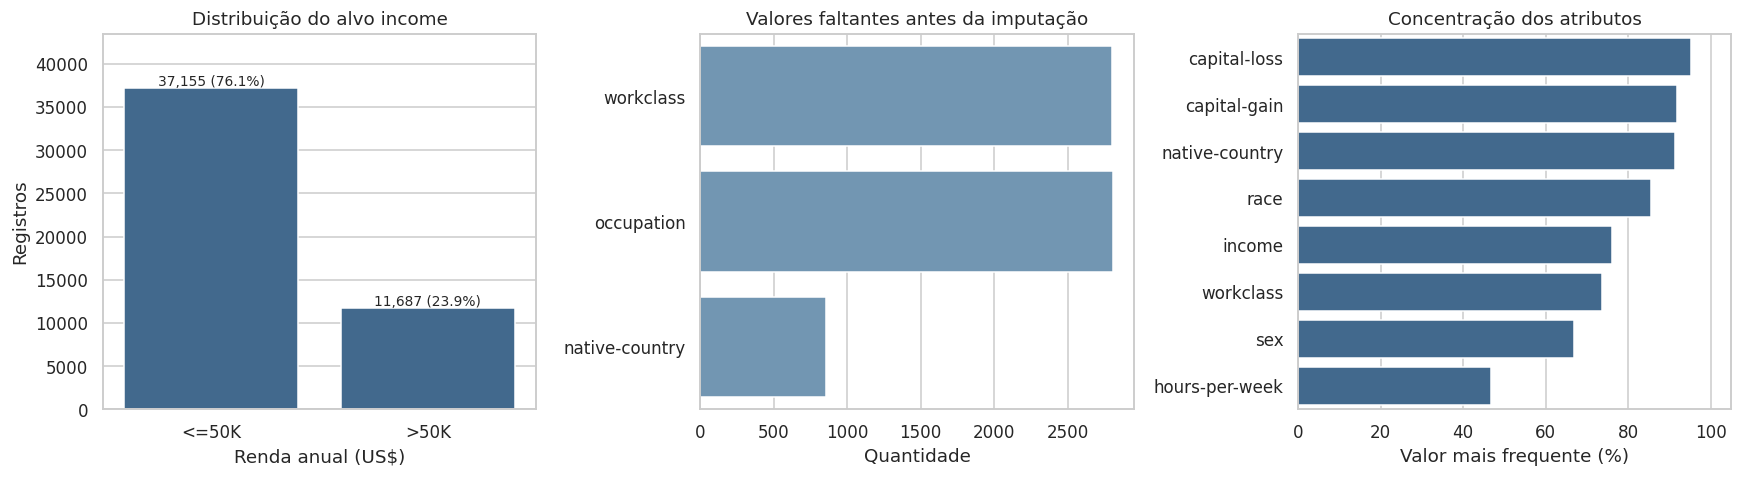

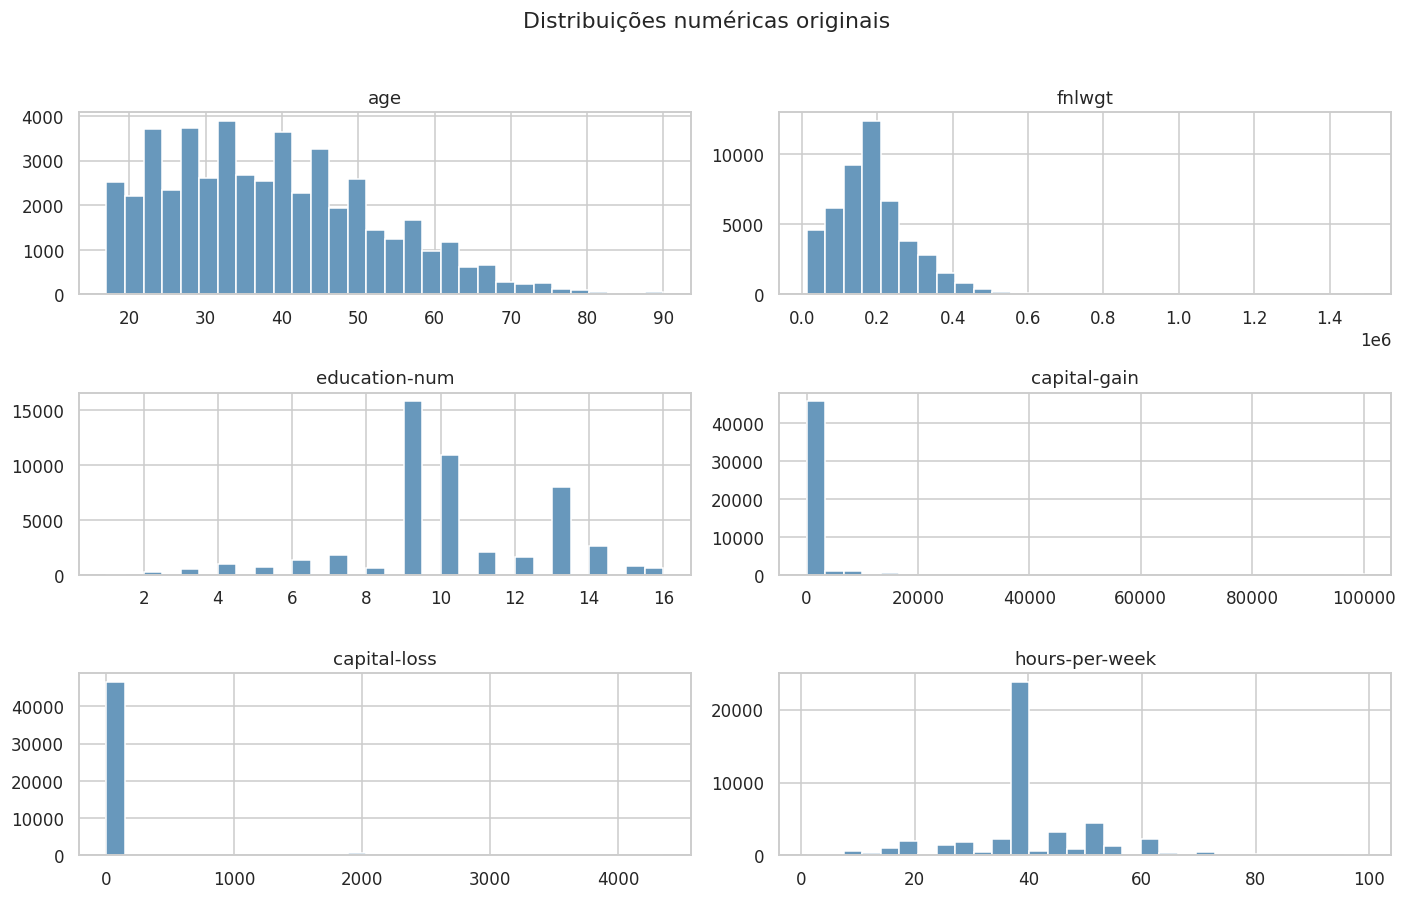

In [10]:
distribuicao_alvo = dataset[target_column].value_counts().reindex(CLASSES).to_frame("Quantidade")
distribuicao_alvo["Proporção (%)"] = distribuicao_alvo["Quantidade"] / len(dataset) * 100
display(distribuicao_alvo.style.format({"Proporção (%)": "{:.2f}%"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(x=distribuicao_alvo.index, y=distribuicao_alvo["Quantidade"], ax=axes[0], color="#356a9a")
axes[0].set(title="Distribuição do alvo income", xlabel="Renda anual (US$)", ylabel="Registros")
for i, (_, row) in enumerate(distribuicao_alvo.iterrows()):
    axes[0].text(i, row["Quantidade"], f"{int(row['Quantidade']):,} ({row['Proporção (%)']:.1f}%)",
                 ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, distribuicao_alvo["Quantidade"].max() * 1.17)
sns.barplot(data=faltantes, x="Ausentes", y="Atributo", ax=axes[1], color="#6898bc")
axes[1].set(title="Valores faltantes antes da imputação", xlabel="Quantidade", ylabel="")
sns.barplot(data=desbalanceamento.head(8), x="Dominância (%)", y="Atributo", ax=axes[2], color="#356a9a")
axes[2].set(title="Concentração dos atributos", xlabel="Valor mais frequente (%)", ylabel="", xlim=(0, 105))
plt.tight_layout()
plt.show()

numericas_originais = dataset.select_dtypes(include="number").columns.tolist()
dataset[numericas_originais].hist(bins=30, figsize=(13, 8), color="#6898bc", edgecolor="white")
plt.suptitle("Distribuições numéricas originais", y=1.02)
plt.tight_layout()
plt.show()

In [11]:
display(pd.DataFrame({
    "Etapa": ["Original", "Após limpeza do alvo", "Entrada dos modelos"],
    "Exemplos": [len(dataset_original), len(dataset), len(dataset)],
    "Preditores": [14, 14, 13], "Alvos": [1, 1, 1],
}))
print("Duplicatas considerando os 13 preditores usados e o alvo:",
      dataset.drop(columns=["fnlwgt"]).duplicated().sum())

,Etapa,Exemplos,Preditores,Alvos
0,Original,48842,14,1
1,Após limpeza do alvo,48842,14,1
2,Entrada dos modelos,48842,13,1


Duplicatas considerando os 13 preditores usados e o alvo: 6374


## 3. Comparação dos três métodos

Os notebooks da árvore e do Random Forest usam o Adult da UCI,
removem `fnlwgt` e mantêm 13 preditores, com divisão estratificada
`test_size=0.30`, `random_state=42`, `stratify=y`. A MLP utiliza a mesma divisão
e acrescenta padronização numérica. Não removemos duplicatas do experimento.

O Random Forest utiliza 100 árvores, critério `entropy`, `max_features="sqrt"`,
`min_samples_leaf=1`, semente 42 e `n_jobs=-1`
Precisão, recall e F1 da tabela principal referem-se à classe positiva `>50K`.

**Tempos distintos:** os notebooks da árvore e da floresta medem **predição**,
não treinamento.A MLP possui
tempo de treino registrado. Os ambientes podem ser diferentes, por isso os tempos
não permitem concluir qual algoritmo é mais rápido em condições equivalentes.

A árvore e a floresta têm métricas de teste arredondadas a quatro casas decimais;
seus relatórios por classe têm duas casas. Não há médias de validação cruzada para
esses dois algoritmos nas fontes atuais. A MLP tem média e desvio padrão em três
partes do treino, apresentados separadamente do teste fixo. A comparação é
descritiva, sem teste de significância ou nova seleção de hiperparâmetros.

In [12]:
REFERENCIA_MLP = {'algoritmo': 'Rede neural MLP',
 'data_utc': '2026-11-25T21:45:38.696451+00:00',
 'hash_csv_fonte': '7bf09a7484d84f92c7e69582078bb01b2f7c4862c8fb27990c0dd848a8a029f4',
 'hash_indices_teste': '74d268808db0373e64c3f42e364d26fb72966f4dfc5919061262ee4e4533c6ba',
 'seed': 42,
 'test_size': 0.3,
 'classe_positiva': '>50K',
 'metricas_teste': {'Acurácia': 0.8563434109056166,
                    'Precisão (>50K)': 0.7385086823289071,
                    'Precisão macro': 0.8121956180507628,
                    'Precisão ponderado': 0.8506206419947129,
                    'Recall (>50K)': 0.6186537364517969,
                    'Recall macro': 0.774878137625737,
                    'Recall ponderado': 0.8563434109056166,
                    'F1 (>50K)': 0.673288840602204,
                    'F1 macro': 0.7906093417899704,
                    'F1 ponderado': 0.8517876636063715},
 'tempo_treino_total_s': 4.152903499999979,
 'preprocessamento': 'Imputação + one-hot + StandardScaler',
 'cv_media': {'Acurácia': 0.8543975993304764,
              'Precisão (>50K)': 0.7313162617722734,
              'Precisão macro': 0.8085807105153823,
              'Precisão ponderado': 0.8488683567340237,
              'Recall (>50K)': 0.6196064050849529,
              'Recall macro': 0.773929656120386,
              'Recall ponderado': 0.8543975993304764,
              'F1 (>50K)': 0.6706095065478029,
              'F1 macro': 0.7885713797358868,
              'F1 ponderado': 0.8500796296494677,
              'Tempo pré-processamento (s)': 0.10010893333336905,
              'Tempo rede (s)': 4.187881466666643,
              'Tempo treino total (s)': 4.2879915666666575,
              'Épocas': 30.333333333333332},
 'cv_desvio': {'Acurácia': 0.0010497579295281167,
               'Precisão (>50K)': 0.012821000959111331,
               'Precisão macro': 0.0044966145328445,
               'Precisão ponderado': 0.0006368450866001537,
               'Recall (>50K)': 0.017606852541284315,
               'Recall macro': 0.005553466198718215,
               'Recall ponderado': 0.0010497579295281167,
               'F1 (>50K)': 0.005296827227952226,
               'F1 macro': 0.002224096772299163,
               'F1 ponderado': 0.0007976232867449539,
               'Tempo pré-processamento (s)': 0.014042092652587802,
               'Tempo rede (s)': 1.5799304630454591,
               'Tempo treino total (s)': 1.5708799680104344,
               'Épocas': 11.503622617824933},
 'versoes': {'numpy': '2.2.6',
             'pandas': '2.2.3',
             'scikit-learn': '1.7.2',
             'matplotlib': '3.10.3',
             'seaborn': '0.13.2',
             'ucimlrepo': '0.0.7',
             'jinja2': '3.1.6'}}
REFERENCIA_MLP["tempo_predicao_s"] = 0.0633
# Tempo de predição da MLP transcrito da saída salva, arredondado a 4 casas.


In [13]:
REFERENCIAS_REPOSITORIO = [{'algoritmo': 'Árvore de decisão',
  'arquivo': 'arvoreDeDecisao.ipynb',
  'commit': '713fa70fddb7579cc07a2b91c05ac7df3ad16b91',
  'sha256_arquivo': '89d17a4b63ddc00cc9100914d453062ca715588c8e7def89bc8a8d1181c7f3ca',
  'metricas_teste': {'Acurácia': 0.823,
                     'Precisão (>50K)': 0.6316,
                     'Recall (>50K)': 0.6244,
                     'F1 (>50K)': 0.6279},
  'tempo_treino_total_s': None,
  'tempo_predicao_s': 0.07501,
  'classes': {'<=50K': {'Precisão': 0.88, 'Recall': 0.89, 'F1': 0.88, 'Suporte': 11147},
              '>50K': {'Precisão': 0.63, 'Recall': 0.62, 'F1': 0.63, 'Suporte': 3506}},
  'origem': 'arvoreDeDecisao.ipynb — commit 713fa70 (saída salva)',
  'preprocessamento': 'Imputação + one-hot'},
 {'algoritmo': 'Random Forest',
  'arquivo': 'FlorestaAleatoria.ipynb',
  'commit': '713fa70fddb7579cc07a2b91c05ac7df3ad16b91',
  'sha256_arquivo': '8530505ee7d5acd4967818c794a61db94982e31dacd585cf1bbc3345a3d278f5',
  'metricas_teste': {'Acurácia': 0.8462,
                     'Precisão (>50K)': 0.7011,
                     'Recall (>50K)': 0.6229,
                     'F1 (>50K)': 0.6597},
  'tempo_treino_total_s': None,
  'tempo_predicao_s': 0.319001,
  'classes': {'<=50K': {'Precisão': 0.89, 'Recall': 0.92, 'F1': 0.9, 'Suporte': 11147},
              '>50K': {'Precisão': 0.7, 'Recall': 0.62, 'F1': 0.66, 'Suporte': 3506}},
  'origem': 'FlorestaAleatoria.ipynb — commit 713fa70 (saída salva)',
  'preprocessamento': 'Imputação + one-hot'}]

In [16]:
EM_COLAB = "google.colab" in sys.modules
PASTA_MLP = (Path("/content/Adult_MLP_resultados") if EM_COLAB else
             Path.home() / "Downloads" / "Adult_MLP_resultados")
ARQUIVO_RESULTADO_MLP = PASTA_MLP / "resultado_comparacao.json"
if ARQUIVO_RESULTADO_MLP.is_file():
    resultado_mlp = json.loads(ARQUIVO_RESULTADO_MLP.read_text(encoding="utf-8"))
    origem_mlp = "Exportação da MLP: " + str(ARQUIVO_RESULTADO_MLP)
else:
    resultado_mlp = REFERENCIA_MLP
    origem_mlp = "Referência salva da MLP em 25/11/2026"
assert resultado_mlp["algoritmo"] == "Rede neural MLP"
hashes_compativeis = {
    hashlib.sha256(
        dataset_original.to_csv(
            index=False,
            lineterminator=fim
        ).encode("utf-8")
    ).hexdigest()
    for fim in ("\n", "\r\n")
}

assert resultado_mlp["hash_csv_fonte"] in hashes_compativeis, (
    "O resultado usa dados diferentes."
)
assert resultado_mlp["hash_indices_teste"] == REFERENCIA_MLP["hash_indices_teste"], "Divisão de teste diferente."
assert resultado_mlp["classe_positiva"] == ">50K"
assert resultado_mlp["seed"] == 42 and resultado_mlp["test_size"] == 0.30
metricas_mlp = resultado_mlp["metricas_teste"]
print("Origem da MLP:", origem_mlp)
print("Data da execução (UTC):", resultado_mlp["data_utc"])
print("SHA-256 dos índices de teste:", resultado_mlp["hash_indices_teste"])

Origem da MLP: Referência salva da MLP em 25/11/2026
Data da execução (UTC): 2026-11-25T21:45:38.696451+00:00
SHA-256 dos índices de teste: 74d268808db0373e64c3f42e364d26fb72966f4dfc5919061262ee4e4533c6ba


,Algoritmo,Protocolo,Acurácia,Precisão (>50K),Recall (>50K),F1 (>50K),Tempo treino total (s)
0,Árvore de decisão,Não disponível na fonte,Não disponível,Não disponível,Não disponível,Não disponível,Não disponível
1,Random Forest,Não disponível na fonte,Não disponível,Não disponível,Não disponível,Não disponível,Não disponível
2,Rede neural MLP,CV 3 partes nos 70% de treino,0.8544 ± 0.0010,0.7313 ± 0.0128,0.6196 ± 0.0176,0.6706 ± 0.0053,4.2880 ± 1.5709


Algoritmo,Acurácia,Precisão (>50K),Recall (>50K),F1 (>50K),Tempo treino total (s),Tempo predição (s),Pré-processamento,Origem
Árvore de decisão,0.8230,0.6316,0.6244,0.6279,Não medido,0.075010,Imputação + one-hot,arvoreDeDecisao.ipynb — commit 713fa70 (saída salva)
Random Forest,0.8462,0.7011,0.6229,0.6597,Não medido,0.319001,Imputação + one-hot,FlorestaAleatoria.ipynb — commit 713fa70 (saída salva)
Rede neural MLP,0.8563,0.7385,0.6187,0.6733,4.1529,0.063300,Imputação + one-hot + StandardScaler,Referência salva da MLP em 25/11/2026


Os tempos são históricos de ambientes possivelmente diferentes; não são um benchmark comum.


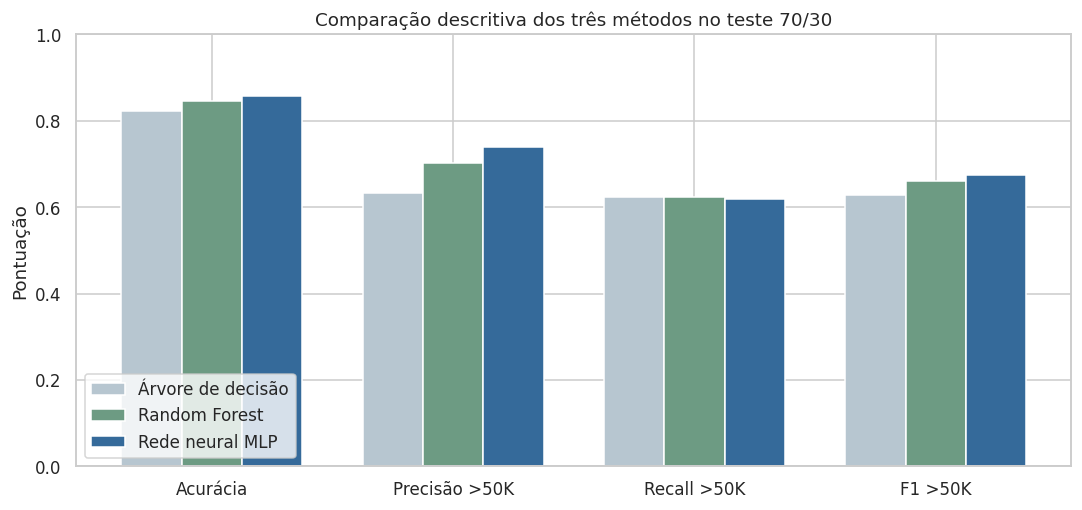

In [17]:
metricas_comparacao = ["Acurácia", "Precisão (>50K)", "Recall (>50K)", "F1 (>50K)"]
colunas_cv = metricas_comparacao + ["Tempo treino total (s)"]
linhas_cv = []
for algoritmo in ["Árvore de decisão", "Random Forest"]:
    linhas_cv.append({"Algoritmo":algoritmo,"Protocolo":"Não disponível na fonte",
                      **{c:"Não disponível" for c in colunas_cv}})
linhas_cv.append({
    "Algoritmo":"Rede neural MLP", "Protocolo":"CV 3 partes nos 70% de treino",
    **{c:f"{resultado_mlp['cv_media'][c]:.4f} ± {resultado_mlp['cv_desvio'][c]:.4f}" for c in colunas_cv},
})
tabela_media=pd.DataFrame(linhas_cv)
display(tabela_media)

linhas_teste=[]
for referencia in REFERENCIAS_REPOSITORIO:
    linhas_teste.append({
        "Algoritmo":referencia["algoritmo"], **referencia["metricas_teste"],
        "Tempo treino total (s)":np.nan,
        "Tempo predição (s)":referencia["tempo_predicao_s"],
        "Pré-processamento":referencia["preprocessamento"], "Origem":referencia["origem"],
    })
linhas_teste.append({
    "Algoritmo":"Rede neural MLP", **{c:metricas_mlp[c] for c in metricas_comparacao},
    "Tempo treino total (s)":resultado_mlp["tempo_treino_total_s"],
    "Tempo predição (s)":resultado_mlp.get("tempo_predicao_s",np.nan),
    "Pré-processamento":resultado_mlp["preprocessamento"], "Origem":origem_mlp,
})
comparacao_referencia=pd.DataFrame(linhas_teste)
display(comparacao_referencia.style.format(
    {**{c:"{:.4f}" for c in metricas_comparacao},
     "Tempo treino total (s)":"{:.4f}", "Tempo predição (s)":"{:.6f}"},na_rep="Não medido"
).hide(axis="index"))
print("Os tempos são históricos de ambientes possivelmente diferentes; não são um benchmark comum.")

fig,ax=plt.subplots(figsize=(10,4.8))
posicoes=np.arange(len(metricas_comparacao))
for i,cor in enumerate(["#b7c6d0","#6d9b83","#356a9a"]):
    ax.bar(posicoes+(i-1)*0.25,
           comparacao_referencia.loc[i,metricas_comparacao].astype(float),width=0.25,
           label=comparacao_referencia.loc[i,"Algoritmo"],color=cor)
ax.set_xticks(posicoes,["Acurácia","Precisão >50K","Recall >50K","F1 >50K"])
ax.set(ylim=(0,1),ylabel="Pontuação",title="Comparação descritiva dos três métodos no teste 70/30")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 4. Interpretação da comparação

In [18]:
linhas_comparacao=[]
for metrica in metricas_comparacao:
    ordenado=comparacao_referencia.sort_values(metrica,ascending=False)
    linhas_comparacao.append({
        "Métrica":metrica,"Maior resultado":ordenado.iloc[0]["Algoritmo"],
        "Maior valor":ordenado.iloc[0][metrica],
        "Menor resultado":ordenado.iloc[-1]["Algoritmo"],"Menor valor":ordenado.iloc[-1][metrica],
    })
display(pd.DataFrame(linhas_comparacao).round(4))
ordenacao_f1=comparacao_referencia.sort_values("F1 (>50K)",ascending=False)
melhor,pior=ordenacao_f1.iloc[0],ordenacao_f1.iloc[-1]
display(Markdown(
    f"Pelo **F1 de >50K**, o maior resultado nas saídas disponíveis é de "
    f"**{melhor['Algoritmo']}** ({melhor['F1 (>50K)']:.4f}) e o menor é de "
    f"**{pior['Algoritmo']}** ({pior['F1 (>50K)']:.4f}). "
    "O Random Forest passa a integrar a comparação como terceiro método. "
    "A tabela por métrica permite verificar que a ordenação pode mudar ao priorizar recall. "
    "Essa ordenação não é um teste de significância nem demonstra superioridade em tempo."
))

,Métrica,Maior resultado,Maior valor,Menor resultado,Menor valor
0,Acurácia,Rede neural MLP,0.8563,Árvore de decisão,0.8230
1,Precisão (>50K),Rede neural MLP,0.7385,Árvore de decisão,0.6316
2,Recall (>50K),Árvore de decisão,0.6244,Rede neural MLP,0.6187
3,F1 (>50K),Rede neural MLP,0.6733,Árvore de decisão,0.6279


Pelo **F1 de >50K**, o maior resultado nas saídas disponíveis é de **Rede neural MLP** (0.6733) e o menor é de **Árvore de decisão** (0.6279). O Random Forest passa a integrar a comparação como terceiro método. A tabela por métrica permite verificar que a ordenação pode mudar ao priorizar recall. Essa ordenação não é um teste de significância nem demonstra superioridade em tempo.

## 5. Exportação opcional da análise

Defina `EXPORTAR = True` para gerar as tabelas de caracterização, comparação e
a referência de MLP utilizada. Os gráficos permanecem salvos neste notebook.
A exportação também cria um ZIP e inicia o download no Colab. Não grava modelos
ou dados de treino: esses arquivos são responsabilidade do notebook da MLP.

In [19]:
EXPORTAR = False
EM_COLAB = "google.colab" in sys.modules
PASTA_EXPORTACAO = (Path("/content/Adult_Analise_resultados") if EM_COLAB else
                    Path.home() / "Downloads" / "Adult_Analise_resultados")
if EXPORTAR:
    import shutil
    PASTA_EXPORTACAO.mkdir(parents=True, exist_ok=True)
    for nome, tabela in {
        "caracterizacao": caracterizacao, "desbalanceamento": desbalanceamento,
        "faltantes": faltantes, "distribuicao_alvo": distribuicao_alvo,
        "disponibilidade_cv": tabela_media, "comparacao_metodos": comparacao_referencia,
    }.items():
        tabela.to_csv(PASTA_EXPORTACAO / f"{nome}.csv", index=True)
    (PASTA_EXPORTACAO / "referencia_mlp_utilizada.json").write_text(
        json.dumps(resultado_mlp, ensure_ascii=False, indent=2), encoding="utf-8")
    (PASTA_EXPORTACAO / "referencias_repositorio.json").write_text(
        json.dumps(REFERENCIAS_REPOSITORIO, ensure_ascii=False, indent=2), encoding="utf-8")
    arquivo_zip = shutil.make_archive(str(PASTA_EXPORTACAO), "zip", root_dir=str(PASTA_EXPORTACAO))
    print("Exportação concluída em:", PASTA_EXPORTACAO.resolve())
    print("ZIP:", arquivo_zip)
    if EM_COLAB:
        from google.colab import files
        files.download(arquivo_zip)
else:
    print("Exportação da análise desativada.")

Exportação da análise desativada.
